In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [65]:
train_data = "oil_presence_trainset.csv"
test_data = "oil_presence_testset.csv"

train_df = pd.read_csv(train_data)
test_df = pd.read_csv(test_data)

In [66]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Rock_Type                  3000 non-null   object 
 1   Porosity                   2197 non-null   float64
 2   Permeability               1814 non-null   float64
 3   Trap_Type                  2233 non-null   object 
 4   Seismic_Score              1950 non-null   float64
 5   Proximity_to_Oil_Field     2057 non-null   float64
 6   Estimated_Reservoir_Depth  1732 non-null   float64
 7   Oil_Presence               3000 non-null   int64  
dtypes: float64(5), int64(1), object(2)
memory usage: 187.6+ KB


In [67]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Rock_Type                  2000 non-null   object 
 1   Porosity                   2000 non-null   float64
 2   Permeability               2000 non-null   float64
 3   Trap_Type                  1514 non-null   object 
 4   Seismic_Score              2000 non-null   float64
 5   Proximity_to_Oil_Field     2000 non-null   float64
 6   Estimated_Reservoir_Depth  2000 non-null   int64  
dtypes: float64(4), int64(1), object(2)
memory usage: 109.5+ KB


In [68]:
#train_df['Rock_Type'] = train_df['Rock_Type'].astype('categorical')

In [69]:
(train_df.isna().sum() / len(train_df) * 100)

Rock_Type                     0.000000
Porosity                     26.766667
Permeability                 39.533333
Trap_Type                    25.566667
Seismic_Score                35.000000
Proximity_to_Oil_Field       31.433333
Estimated_Reservoir_Depth    42.266667
Oil_Presence                  0.000000
dtype: float64

In [70]:
num_col = train_df.columns.drop(['Oil_Presence', 'Rock_Type', 'Trap_Type'])

In [71]:
train_df.head()

,Rock_Type,Porosity,Permeability,Trap_Type,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Oil_Presence
0,Limestone,17.667992,834.277472,NaN,0.705933,2.431355,2228.0,1
1,Limestone,27.665758,578.158034,NaN,0.545806,2.606158,1610.0,0
2,Sandstone,28.855946,404.790685,NaN,0.167530,1.143136,2344.0,0
3,Sandstone,0.410957,887.836673,Dome,0.026852,2.673532,NaN,0
4,Shale,16.490538,562.288802,NaN,NaN,2.064440,NaN,0


In [72]:
train_df.describe(include=['max', 'min', 'mean', 'std'])

,Column,Max,Min
0,Porosity,29.992547,0.018825
1,Permeability,997.134762,1.185010
2,Seismic_Score,0.999353,0.000333
3,Proximity_to_Oil_Field,4.998872,0.001007
4,Estimated_Reservoir_Depth,4997.000000,500.000000


This cell introduces a reusable helper function, `create_comparison_df`, that compares the numerical columns of the training and test datasets by calculating key summary statistics—maximum, minimum, mean, and standard deviation. The resulting table places the train and test summaries side by side for each feature, making it easier to inspect whether both datasets have similar distributions before further preprocessing or modeling.


In [73]:
def create_comparison_df(df1, df2):

    """
    This function creates a comparison DataFrame between two input DataFrames by computing
    specific statistical metrics (such as max, min, mean, and standard deviation) on their
    numerical columns. It returns a DataFrame that concatenates these statistical summaries
    side-by-side for easy comparison.

    :param df1: A pandas DataFrame representing the first dataset.
    :param df2: A pandas DataFrame representing the second dataset.
    :return: A pandas DataFrame containing a vertical comparison of statistical summaries
        (max, min, mean, std) for the numerical columns of the two input DataFrames.
    """

    # Isolate only the numerical columns to avoid errors with string/object types
    df1_num = df1.select_dtypes(include='number')
    df2_num = df2.select_dtypes(include='number')

    # Definning specific metrics to extract
    metrics = ['max', 'min', 'mean', 'std']

    # Calculate the statistics and transpose (.T) so features become rows
    df1_stats = df1_num.agg(metrics).T
    df2_stats = df2_num.agg(metrics).T

    # Create a 'Dataset' column to distinguish between Train and Test sets
    df1_stats['Dataset'] = 'Train'
    df2_stats['Dataset'] = 'Test'

    # Concatenate vertically
    combined_df = pd.concat([df1_stats, df2_stats])

    # Name the current index 'Feature', then create the MultiIndex
    combined_df.index.name = 'Feature'
    comparison_df = combined_df.reset_index().set_index(['Feature', 'Dataset'])

    # Sort the index so 'Train' and 'Test' are grouped together under each Feature
    comparison_df = comparison_df.sort_index()

    return comparison_df

# Generate and inspect the new DataFrame
summary_df = create_comparison_df(train_df, test_df)
summary_df

max         min         mean  \
Feature                   Dataset                                         
Estimated_Reservoir_Depth Test     4996.000000  500.000000  2744.918000   
                          Train    4997.000000  500.000000  2764.426674   
Oil_Presence              Train       1.000000    0.000000     0.277667   
Permeability              Test      999.707930    2.130344   501.197066   
                          Train     997.134762    1.185010   505.594049   
Porosity                  Test       29.907277    0.005596    15.169888   
                          Train      29.992547    0.018825    14.762194   
Proximity_to_Oil_Field    Test        4.999111    0.004825     2.463405   
                          Train       4.998872    0.001007     2.545868   
Seismic_Score             Test        0.999695    0.000009     0.497805   
                          Train       0.999353    0.000333     0.490680   

                                           std  
Feature                   Dataset               
Estimated_Reservoir_Depth Test     1301.672457  
                          Train    1288.782908  
Oil_Presence              Train       0.447923  
Permeability              Test      291.499605  
                          Train     281.718143  
Porosity                  Test        8.576058  
                          Train       8.750759  
Proximity_to_Oil_Field    Test        1.433698  
                          Train       1.470783  
Seismic_Score             Test        0.289563  
                          Train       0.286654

In [74]:
train_df[train_df['Trap_Type'].isna()]

,Rock_Type,Porosity,Permeability,Trap_Type,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Oil_Presence
0,Limestone,17.667992,834.277472,NaN,0.705933,2.431355,2228.0,1
1,Limestone,27.665758,578.158034,NaN,0.545806,2.606158,1610.0,0
2,Sandstone,28.855946,404.790685,NaN,0.167530,1.143136,2344.0,0
4,Shale,16.490538,562.288802,NaN,NaN,2.064440,NaN,0
17,Sandstone,NaN,286.076025,NaN,0.972294,0.565441,916.0,0
...,...,...,...,...,...,...,...,...
2947,Shale,0.146534,849.813714,NaN,0.051516,NaN,NaN,0
2965,Limestone,21.205136,367.626274,NaN,NaN,2.745641,3751.0,0
2972,Limestone,NaN,NaN,NaN,NaN,3.109198,2477.0,0
2973,Limestone,6.196032,466.836687,NaN,NaN,NaN,3820.0,0


In [75]:
train_df['Trap_Type'].unique()

array([nan, 'Dome', 'Anticline', 'Fault'], dtype=object)

In [76]:
# Filling nan in 'Trap_Type' column
train_df['Trap_Type'] = train_df['Trap_Type'].fillna('None')

# Only 'Trap_Type' column containing missing values in test dataset
test_df['Trap_Type'] = test_df['Trap_Type'].fillna('None')

In [77]:
train_df['Trap_Type'].value_counts()

Trap_Type
None         767
Fault        766
Anticline    757
Dome         710
Name: count, dtype: int64

In [78]:
train_df['Rock_Type'].unique()

array(['Limestone', 'Sandstone', 'Shale'], dtype=object)

This cell computes and visualizes the Pearson correlation matrix for the numeric training features, including the target variable `Oil_Presence`. It helps identify which continuous variables have stronger positive or negative linear relationships with oil presence, while the sorted target-correlation table provides a focused summary for feature interpretation before preprocessing and model development.


In [ ]:
# Set a clean, minimalist aesthetic for the plots
sns.set_theme(style="white")

plt.figure(figsize=(12, 8))

# Calculate the Pearson correlation matrix on the fully complete dataset
corr_matrix = train_df.select_dtypes(include='number').corr()

# Isolate the correlations specifically related to our target variable, sorted for readability
target_corr = corr_matrix[['Oil_Presence']].sort_values(by='Oil_Presence', ascending=False)

# Plot the heatmap
sns.heatmap(
    corr_matrix,
    annot=True,          # Display the correlation coefficients
    cmap='vlag',         # A clean blue-to-red diverging colormap
    fmt=".2f",           # Round to 2 decimal places for neatness
    linewidths=0.5,      # Add gridlines for readability
    cbar_kws={"shrink": .8}
)

plt.title("Feature Correlation Heatmap", pad=20, fontsize=14)
plt.tight_layout()
plt.show()

# Print the direct target correlations as a clean summary
print("--- Correlation with Oil_Presence ---")
display(target_corr)

## Part 1: Standard Training Data Transformation

The next cell prepares the training dataset for the Part-1 modeling requirement using a standard machine learning preprocessing workflow. It separates the target variable (`Oil_Presence`) from the input features, identifies numerical and categorical columns, then applies appropriate transformations to each group.

Numerical features are filled using median imputation and standardized so they are on a comparable scale. Categorical features are filled with `"None"` where needed and converted into numeric one-hot encoded columns. These steps are combined into a single `ColumnTransformer`, which is fit on the training data and used to create the transformed Part-1 training feature matrix.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate the features (X) from the target variable (y)
X_train = train_df.drop(columns=['Oil_Presence'])
y_train = train_df['Oil_Presence']

# Group the features by type
numerical_cols = [
    'Porosity',
    'Permeability',
    'Seismic_Score',
    'Proximity_to_Oil_Field',
    'Estimated_Reservoir_Depth'
]
categorical_cols = ['Rock_Type', 'Trap_Type']

# Create the Numerical Pipeline
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Create the Categorical Pipeline
# We fill any lingering missing values with 'None' and apply One-Hot Encoding.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Bundle the pipelines together into a ColumnTransformer
preprocessor_p1 = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Fit the preprocessor on the training data and transform
train_p1 = preprocessor_p1.fit_transform(X_train)

# --- Verification ---
print(f"Part-1 Training Features Shape: {train_p1.shape}")

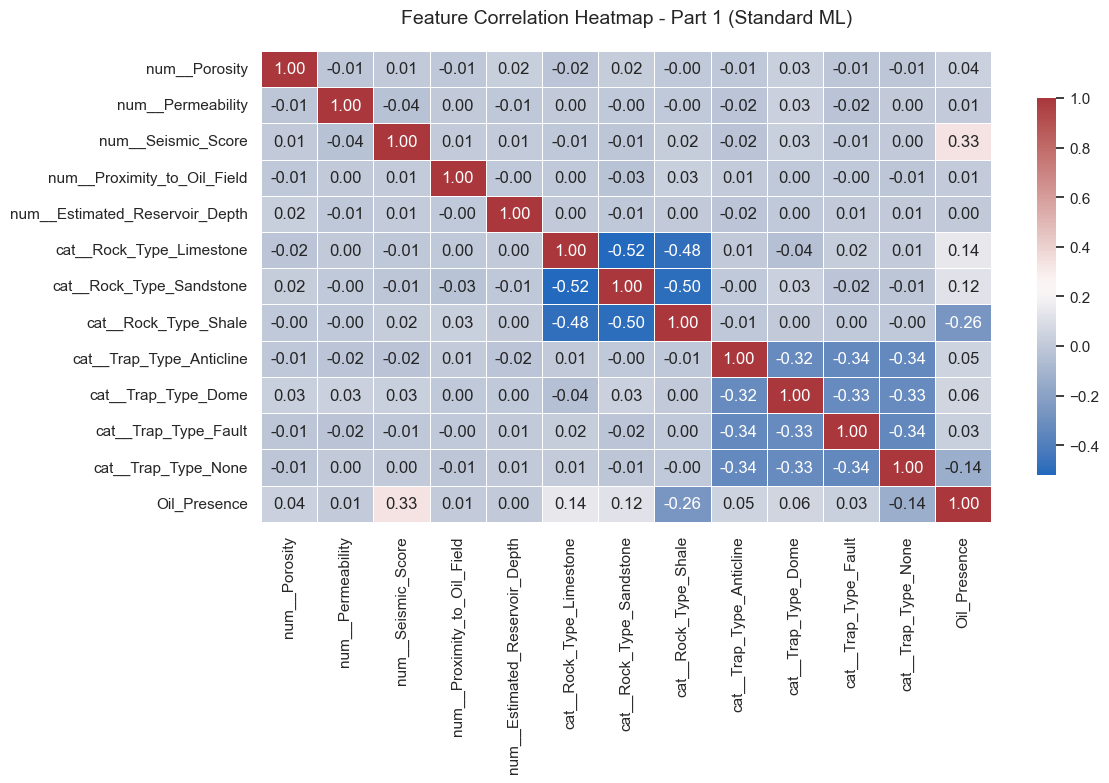

--- Correlation with Oil_Presence (Part 1 Data) ---


,Oil_Presence
Oil_Presence,1.000000
num__Seismic_Score,0.332367
cat__Rock_Type_Limestone,0.143572
cat__Rock_Type_Sandstone,0.116270
cat__Trap_Type_Dome,0.057537
cat__Trap_Type_Anticline,0.049362
num__Porosity,0.037761
cat__Trap_Type_Fault,0.031249
num__Permeability,0.013662
num__Proximity_to_Oil_Field,0.012005


In [81]:
# Extract the newly generated column names from the pipeline
feature_names = preprocessor_p1.get_feature_names_out()

# Convert the NumPy array back into a readable Pandas DataFrame
train_part1 = pd.DataFrame(train_p1, columns=feature_names)

# 3. Reattach the target variable for correlation calculation
# We use .reset_index(drop=True) to ensure the rows align perfectly after the split
train_part1['Oil_Presence'] = y_train.reset_index(drop=True)

# 4. Calculate the correlation matrix
corr_matrix_p1 = train_part1.corr()
target_corr_p1 = corr_matrix_p1[['Oil_Presence']].sort_values(by='Oil_Presence', ascending=False)

# 5. Plot the Heatmap
sns.set_theme(style="white")
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix_p1,
    annot=True,
    cmap='vlag',
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title("Feature Correlation Heatmap - Part 1 (Standard ML)", pad=20, fontsize=14)
plt.tight_layout()
plt.show()

# Print the direct target correlations as a clean summary
print("--- Correlation with Oil_Presence (Part 1 Data) ---")
display(target_corr_p1)

This step separates the training data into two groups: rows with complete information and rows containing missing values. The complete rows provide a clean baseline for understanding valid geological patterns, validating potential anomalies, and guiding the imputation process used to fill missing values in the incomplete rows.


In [82]:
# Isolate the complete and incomplete rows for the Training set
train_complete = train_df.dropna()
train_incomplete = train_df[train_df.isnull().any(axis=1)]

# Print a quick diagnostic to see the size of the gaps
print("--- Training Data ---")
print(f"Total Rows: {len(train_df)}")
print(f"Complete Rows (Clean Baseline): {len(train_complete)}")
print(f"Incomplete Rows (To Impute Later): {len(train_incomplete)}\n")

--- Training Data ---
Total Rows: 3000
Complete Rows (Clean Baseline): 355
Incomplete Rows (To Impute Later): 2645



In [83]:
def check_distribution(df, column_name):
    # Calculate absolute counts and percentages
    counts = df[column_name].value_counts()
    percentages = df[column_name].value_counts(normalize=True) * 100

    # Combine into a clean, readable dataframe
    dist_df = pd.concat([counts, percentages], axis=1, keys=['Count', 'Percentage (%)'])
    dist_df['Percentage (%)'] = dist_df['Percentage (%)'].round(2)

    return dist_df

# Checking categorical distribution in 'train_complete'
print("--- Rock_Type Distribution (Clean Baseline) ---")
display(check_distribution(train_complete, 'Rock_Type'))

print("\n--- Trap_Type Distribution (Clean Baseline) ---")
display(check_distribution(train_complete, 'Trap_Type'))

--- Rock_Type Distribution (Clean Baseline) ---


,Count,Percentage (%)
Rock_Type,,
Sandstone,120,33.80
Shale,119,33.52
Limestone,116,32.68



--- Trap_Type Distribution (Clean Baseline) ---


,Count,Percentage (%)
Trap_Type,,
None,113,31.83
Anticline,99,27.89
Dome,75,21.13
Fault,68,19.15


In [84]:
#Checking categorical distribution in 'train_df'
print("--- Rock_Type Distribution (Total Rows) ---")
display(check_distribution(train_df, 'Rock_Type'))

print("\n--- Trap_Type Distribution (Total Rows) ---")
display(check_distribution(train_df, 'Trap_Type'))

--- Rock_Type Distribution (Total Rows) ---


,Count,Percentage (%)
Rock_Type,,
Sandstone,1043,34.77
Limestone,1008,33.60
Shale,949,31.63



--- Trap_Type Distribution (Total Rows) ---


,Count,Percentage (%)
Trap_Type,,
None,767,25.57
Fault,766,25.53
Anticline,757,25.23
Dome,710,23.67


In [85]:
display(train_complete[train_complete['Rock_Type'] == 'Shale'])

,Rock_Type,Porosity,Permeability,Trap_Type,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Oil_Presence
5,Shale,16.654792,979.154784,Anticline,0.044457,4.927771,3556.0,1
21,Shale,12.704460,268.577076,Anticline,0.399866,0.939488,618.0,0
77,Shale,25.749913,161.885169,Anticline,0.911608,1.091911,4376.0,0
87,Shale,6.771832,277.720821,None,0.618353,4.529201,3078.0,1
92,Shale,16.931861,262.363181,Fault,0.639540,1.820055,1724.0,0
...,...,...,...,...,...,...,...,...
2943,Shale,13.908662,321.700505,None,0.349119,3.237683,2398.0,0
2953,Shale,28.639205,163.297754,Anticline,0.605906,4.892097,1199.0,0
2970,Shale,5.415547,225.681065,Anticline,0.091349,1.082354,3280.0,0
2984,Shale,18.113910,739.868361,Anticline,0.319044,3.757537,3544.0,0


Checking for anomalies

In [86]:
# The Shale-Permeability Contradiction
# Shale is a barrier rock. It should not have high permeability.
# We will flag any Shale with a permeability > 10 mD as a physical anomaly.
shale_anomaly = train_complete[(train_complete['Rock_Type'] == 'Shale') & (train_complete['Permeability'] > 10)]

# 2. The Seismic-Trap Disconnect
# A trap type of 'None' means no structure exists. A very high seismic score contradicts this.
# We will flag 'None' traps with a Seismic_Score > 0.8.
seismic_trap_anomaly = train_complete[(train_complete['Trap_Type'] == 'None') & (train_complete['Seismic_Score'] > 0.8)]

# 3. The 'None' Trap Oil Accumulation
# Oil needs a trap to accumulate. If the trap is 'None' but Oil_Presence is 1, this violates accumulation mechanics.
trap_oil_anomaly = train_complete[(train_complete['Trap_Type'] == 'None') & (train_complete['Oil_Presence'] == 1)]

# 4. The Depth-Porosity Contradiction (Mechanical Compaction)
# Deep rocks are heavily crushed by pressure. High porosity at high depths defies mechanical compaction.
# We will flag extreme cases: Depth > 4000m AND Porosity > 25%.
depth_porosity_anomaly = train_complete[(train_complete['Estimated_Reservoir_Depth'] > 4000) & (train_complete['Porosity'] > 25)]

# --- Generate the Diagnostic Report ---
print("--- Physical Anomaly Detection Report (Baseline) ---")
print(f"Shale-Permeability Anomalies: {len(shale_anomaly)}")
print(f"Seismic-Trap Anomalies: {len(seismic_trap_anomaly)}")
print(f"Trap-Oil Accumulation Anomalies: {len(trap_oil_anomaly)}")
print(f"Depth-Porosity Anomalies: {len(depth_porosity_anomaly)}")

# Combine indices to see exactly how many unique rows are poisoned
all_anomaly_indices = set(shale_anomaly.index) | set(seismic_trap_anomaly.index) | \
                      set(trap_oil_anomaly.index) | set(depth_porosity_anomaly.index)

print(f"\nTotal Unique Anomalous Rows to Drop/Fix: {len(all_anomaly_indices)}")

--- Physical Anomaly Detection Report (Baseline) ---
Shale-Permeability Anomalies: 119
Seismic-Trap Anomalies: 24
Trap-Oil Accumulation Anomalies: 21
Depth-Porosity Anomalies: 15

Total Unique Anomalous Rows to Drop/Fix: 150


This cell documents the next step, where the notebook defines `apply_physics_corrections` to clean the complete training baseline using geology-based rules. The function corrects unrealistic shale permeability, adjusts overly high porosity at deep reservoir depths, resets oil presence where no trap exists, and removes ambiguous high-seismic rows with no trap structure. The cleaned output, `train_physics_clean`, provides a more physically consistent baseline for later imputation and modeling.


In [87]:
def apply_physics_corrections(df):
    # Create a copy
    df_clean = df.copy()

    # Correct Shale Rock Permeability
    shale_mask = df_clean['Rock_Type'] == 'Shale'
    df_clean.loc[shale_mask, 'Permeability'] = 1.0

    # Correct Porosity for 4000m+ depths
    depth_mask = (df_clean['Estimated_Reservoir_Depth'] > 4000) & (df_clean['Porosity'] > 25)
    df_clean.loc[depth_mask, 'Porosity'] = 15.0

    # Correct Oil Presence for Trap_Type = 'None'
    trap_oil_mask = (df_clean['Trap_Type'] == 'None') & (df_clean['Oil_Presence'] == 1)
    df_clean.loc[trap_oil_mask, 'Oil_Presence'] = 0

    # Drop the unresolved Seismic-Trap anomalies (too ambiguous to safely guess the trap)
    seismic_trap_mask = (df_clean['Trap_Type'] == 'None') & (df_clean['Seismic_Score'] > 0.8)
    df_clean = df_clean[~seismic_trap_mask]

    return df_clean

# Apply corrections to the baseline
train_physics_clean = apply_physics_corrections(train_complete)

print(f"Original Baseline Rows: {len(train_complete)}")
print(f"Final Purified Baseline Rows: {len(train_physics_clean)}")

Original Baseline Rows: 355
Final Purified Baseline Rows: 331


--- Sandstone Mathematical Baseline ---
Equation: log10(k) = -0.0081 * phi + 2.6712
R-squared: 0.0310

--- Limestone Mathematical Baseline ---
Equation: log10(k) = 0.0026 * phi + 2.5544
R-squared: 0.0043



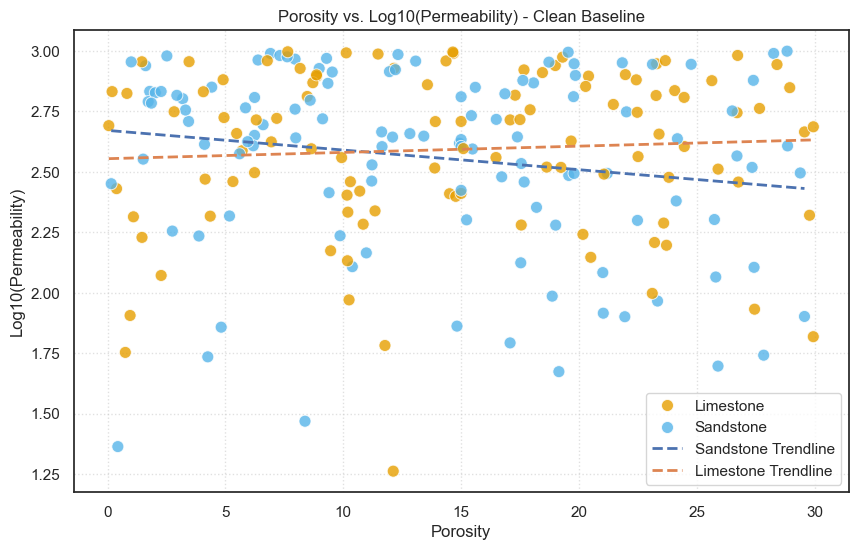

In [88]:
from scipy.stats import linregress

# 1. Isolate the reservoir rocks (Shale is already corrected and acts differently)
reservoir_rocks = train_physics_clean[train_physics_clean['Rock_Type'].isin(['Sandstone', 'Limestone'])].copy()

# 2. Calculate the base-10 logarithm of Permeability
reservoir_rocks['Log10_Permeability'] = np.log10(reservoir_rocks['Permeability'])

# 3. Setup the visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=reservoir_rocks,
    x='Porosity',
    y='Log10_Permeability',
    hue='Rock_Type',
    palette=['#E69F00', '#56B4E9'], # Colorblind-friendly palette
    s=75,
    alpha=0.8
)

# 4. Calculate constants (A and B) and plot trendlines
for rock in ['Sandstone', 'Limestone']:
    rock_data = reservoir_rocks[reservoir_rocks['Rock_Type'] == rock]

    # Run linear regression
    slope, intercept, r_value, p_value, std_err = linregress(
        rock_data['Porosity'],
        rock_data['Log10_Permeability']
    )

    # Output the mathematical baseline
    print(f"--- {rock} Mathematical Baseline ---")
    print(f"Equation: log10(k) = {slope:.4f} * phi + {intercept:.4f}")
    print(f"R-squared: {r_value**2:.4f}\n")

    # Plot the trendline
    x_vals = np.array([rock_data['Porosity'].min(), rock_data['Porosity'].max()])
    y_vals = slope * x_vals + intercept
    plt.plot(x_vals, y_vals, label=f'{rock} Trendline', linewidth=2, linestyle='--')

# Finalize plot formatting
plt.title("Porosity vs. Log10(Permeability) - Clean Baseline")
plt.xlabel("Porosity")
plt.ylabel("Log10(Permeability)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

This cell builds a physics-informed imputation workflow to complete the training dataset. It recombines the cleaned complete baseline with the incomplete rows, applies a strict shale permeability rule before imputation, one-hot encodes the categorical geological features, and uses `KNNImputer` to estimate missing numerical values based on similar reservoirs. After imputation, the numerical features are clipped to realistic physical limits, and the original `Rock_Type` and `Trap_Type` text columns are restored for easier downstream analysis and modeling.


In [89]:
from sklearn.impute import KNNImputer

# 1. Recombine the purified baseline with the incomplete data
train_working = pd.concat([train_physics_clean, train_incomplete]).copy()

# 2. Physics Override: Shale Permeability
# We strictly enforce the barrier rock rule before the algorithm touches it.
shale_missing_perm = (train_working['Rock_Type'] == 'Shale') & (train_working['Permeability'].isnull())
train_working.loc[shale_missing_perm, 'Permeability'] = 1.0

# 3. One-Hot Encoding (OHE)
# Convert Rock_Type and Trap_Type into binary numerical columns (1s and 0s)
# Setting dtype=float ensures the KNNImputer reads them perfectly.
train_encoded = pd.get_dummies(
    train_working,
    columns=['Rock_Type', 'Trap_Type'],
    dtype=float
)

# 4. Define the Feature Space
# We grab the core numericals PLUS all the new binary columns we just created.
# CRITICAL: We strictly exclude 'Oil_Presence' to prevent data leakage.
knn_features = [
    'Estimated_Reservoir_Depth',
    'Seismic_Score',
    'Porosity',
    'Permeability'
] + [col for col in train_encoded.columns if 'Rock_Type_' in col or 'Trap_Type_' in col]

# 5. Initialize the Smart Imputer
# Distance weighting means a neighbor with the exact same rock and trap type
# will heavily dominate the average.
imputer = KNNImputer(n_neighbors=5, weights='distance')

# 6. Execute the Imputation across the entire dataset
train_encoded[knn_features] = imputer.fit_transform(train_encoded[knn_features])

# 7. Clamp to the Datathon Physical Boundaries
train_encoded['Porosity'] = train_encoded['Porosity'].clip(lower=0, upper=30)
train_encoded['Permeability'] = train_encoded['Permeability'].clip(lower=1, upper=1000)
train_encoded['Estimated_Reservoir_Depth'] = train_encoded['Estimated_Reservoir_Depth'].clip(lower=0, upper=5000)
train_encoded['Seismic_Score'] = train_encoded['Seismic_Score'].clip(lower=0, upper=1)

# 8. Restore the original text columns for easier modeling/EDA later
train_encoded['Rock_Type'] = train_working['Rock_Type']
train_encoded['Trap_Type'] = train_working['Trap_Type']

In [90]:
train_encoded.isna().sum()

Porosity                       0
Permeability                   0
Seismic_Score                  0
Proximity_to_Oil_Field       943
Estimated_Reservoir_Depth      0
Oil_Presence                   0
Rock_Type_Limestone            0
Rock_Type_Sandstone            0
Rock_Type_Shale                0
Trap_Type_Anticline            0
Trap_Type_Dome                 0
Trap_Type_Fault                0
Trap_Type_None                 0
Rock_Type                      0
Trap_Type                      0
dtype: int64

In [91]:
train_encoded.describe()

,Porosity,Permeability,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Oil_Presence,Rock_Type_Limestone,Rock_Type_Sandstone,Rock_Type_Shale,Trap_Type_Anticline,Trap_Type_Dome,Trap_Type_Fault,Trap_Type_None
count,2976.000000,2976.000000,2976.000000,2033.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000,2976.000000
mean,14.705038,426.634135,0.482196,2.548195,2710.783586,0.272849,0.335349,0.348790,0.315860,0.254368,0.238575,0.257392,0.249664
std,7.724663,293.278009,0.245168,1.471528,1053.906569,0.445499,0.472192,0.476668,0.464936,0.435579,0.426284,0.437271,0.432891
min,0.018825,1.000000,0.000333,0.001007,500.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,8.956027,162.187904,0.308796,1.282191,1978.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,14.775011,448.963576,0.477957,2.568633,2705.168029,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,20.367671,650.253775,0.654925,3.850428,3425.156755,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000
max,29.992547,997.134762,0.999246,4.998872,4997.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [92]:
# 1. Define the feature space for this specific imputation
# We include all the restored numericals and One-Hot Encoded columns,
# PLUS the Proximity column we want to fix.
# We strictly EXCLUDE 'Oil_Presence'.
proximity_features = [
    'Estimated_Reservoir_Depth',
    'Seismic_Score',
    'Porosity',
    'Permeability',
    'Proximity_to_Oil_Field'
] + [col for col in train_encoded.columns if 'Rock_Type_' in col or 'Trap_Type_' in col]

# 2. Execute the Imputation
train_encoded[proximity_features] = imputer.fit_transform(train_encoded[proximity_features])

# 3. Clamp to the Datathon Physical Boundaries
# Proximity to the nearest oil field must be between 0 and 5 km.
train_encoded['Proximity_to_Oil_Field'] = train_encoded['Proximity_to_Oil_Field'].clip(lower=0, upper=5)

# --- Final Verification ---
print("--- Final Dataset Health Check ---")
print(train_encoded.isna().sum())
print("\nCongratulations, the dataset is 100% complete and physics-compliant.")

--- Final Dataset Health Check ---
Porosity                     0
Permeability                 0
Seismic_Score                0
Proximity_to_Oil_Field       0
Estimated_Reservoir_Depth    0
Oil_Presence                 0
Rock_Type_Limestone          0
Rock_Type_Sandstone          0
Rock_Type_Shale              0
Trap_Type_Anticline          0
Trap_Type_Dome               0
Trap_Type_Fault              0
Trap_Type_None               0
Rock_Type                    0
Trap_Type                    0
dtype: int64

Congratulations, the dataset is 100% complete and physics-compliant.


In [93]:
# Clean dataframe by dropping temporary encoded column
one_hot_enc_cols = [col for col in train_encoded.columns if 'Rock_Type_' in col or 'Trap_Type_' in col]
train_part2 = train_encoded.drop(columns=one_hot_enc_cols).copy()
train_part2.columns

Index(['Porosity', 'Permeability', 'Seismic_Score', 'Proximity_to_Oil_Field',
       'Estimated_Reservoir_Depth', 'Oil_Presence', 'Rock_Type', 'Trap_Type'],
      dtype='object')

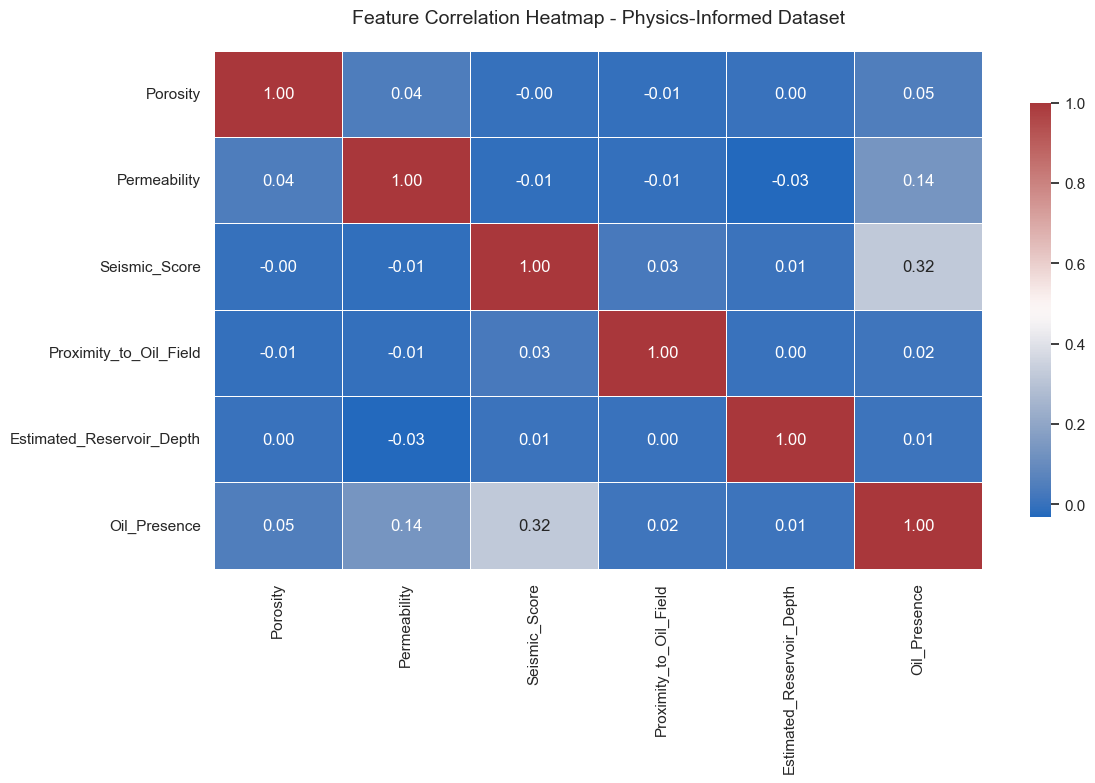

--- Correlation with Oil_Presence ---


,Oil_Presence
Oil_Presence,1.000000
Seismic_Score,0.319582
Permeability,0.136689
Porosity,0.047667
Proximity_to_Oil_Field,0.015033
Estimated_Reservoir_Depth,0.012393


In [94]:
# Set a clean, minimalist aesthetic for the plots
sns.set_theme(style="white")

plt.figure(figsize=(12, 8))

# Calculate the Pearson correlation matrix on the fully complete dataset
corr_matrix = train_part2.select_dtypes(include='number').corr()

# Isolate the correlations specifically related to our target variable, sorted for readability
target_corr = corr_matrix[['Oil_Presence']].sort_values(by='Oil_Presence', ascending=False)

# Plot the heatmap
sns.heatmap(
    corr_matrix,
    annot=True,          # Display the correlation coefficients
    cmap='vlag',         # A clean blue-to-red diverging colormap
    fmt=".2f",           # Round to 2 decimal places for neatness
    linewidths=0.5,      # Add gridlines for readability
    cbar_kws={"shrink": .8}
)

plt.title("Feature Correlation Heatmap - Physics-Informed Dataset", pad=20, fontsize=14)
plt.tight_layout()
plt.show()

# Print the direct target correlations as a clean summary
print("--- Correlation with Oil_Presence ---")
display(target_corr)

--- Target Balance (Oil_Presence) ---
Dry Hole (0): 2164 rows (72.72%)
Oil Present (1): 812 rows (27.28%)


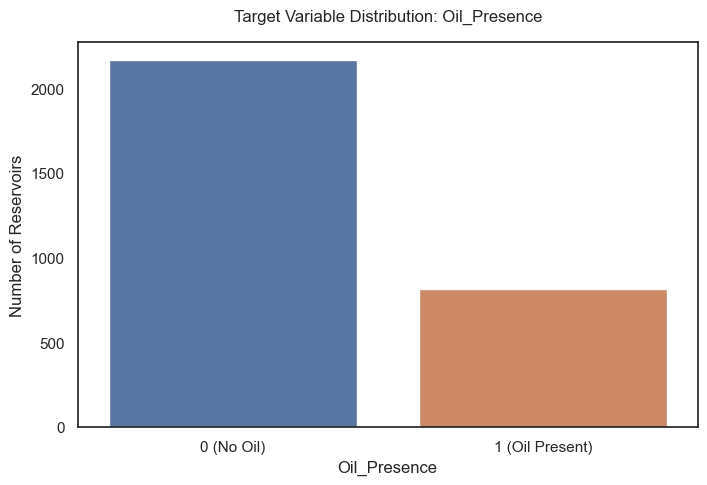

In [95]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Calculate absolute counts and percentages for Oil_Presence
balance_counts = train_part2['Oil_Presence'].value_counts()
balance_percentages = train_part2['Oil_Presence'].value_counts(normalize=True) * 100

# 3. Print the text breakdown
print("--- Target Balance (Oil_Presence) ---")
for val, count in balance_counts.items():
    status = "Oil Present (1)" if val == 1 else "Dry Hole (0)"
    print(f"{status}: {count} rows ({balance_percentages[val]:.2f}%)")

# 4. Visualize the distribution
plt.figure(figsize=(8, 5))
sns.countplot(
    data=train_part2,
    x='Oil_Presence',
    hue='Oil_Presence',
    legend=False
)
plt.title("Target Variable Distribution: Oil_Presence", pad=15)
plt.xticks(ticks=[0, 1], labels=['0 (No Oil)', '1 (Oil Present)'])
plt.ylabel("Number of Reservoirs")
plt.show()

In [96]:
train_part1.head()

,num__Porosity,num__Permeability,num__Seismic_Score,num__Proximity_to_Oil_Field,num__Estimated_Reservoir_Depth,cat__Rock_Type_Limestone,cat__Rock_Type_Sandstone,cat__Rock_Type_Shale,cat__Trap_Type_Anticline,cat__Trap_Type_Dome,cat__Trap_Type_Fault,cat__Trap_Type_None,Oil_Presence
0,0.393809,1.502660,0.938897,-0.095252,-0.551433,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1
1,1.729120,0.333192,0.245890,0.048313,-1.182706,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0
2,1.888082,-0.458422,-1.391246,-1.153260,-0.432942,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0
3,-1.911057,1.747216,-2.000087,0.103647,0.004761,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
4,0.236547,0.260731,-0.013571,-0.396597,0.004761,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0


In [97]:
train_encoded.head()

,Porosity,Permeability,Seismic_Score,Proximity_to_Oil_Field,Estimated_Reservoir_Depth,Oil_Presence,Rock_Type_Limestone,Rock_Type_Sandstone,Rock_Type_Shale,Trap_Type_Anticline,Trap_Type_Dome,Trap_Type_Fault,Trap_Type_None,Rock_Type,Trap_Type
0,17.667992,834.277472,0.705933,2.431355,2228.0,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,Limestone,None
1,27.665758,578.158034,0.545806,2.606158,1610.0,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,Limestone,None
2,28.855946,404.790685,0.167530,1.143136,2344.0,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,Sandstone,None
5,16.654792,1.000000,0.044457,4.927771,3556.0,1,0.0,0.0,1.0,1.0,0.0,0.0,0.0,Shale,Anticline
21,12.704460,1.000000,0.399866,0.939488,618.0,0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,Shale,Anticline


In [98]:
# Clean the names by stripping out 'num__' and 'cat__'
train_part1.columns = train_part1.columns.str.replace('num__', '').str.replace('cat__', '')

print("--- Cleaned Part-1 Columns ---")
print(train_part1.columns.tolist())

--- Cleaned Part-1 Columns ---
['Porosity', 'Permeability', 'Seismic_Score', 'Proximity_to_Oil_Field', 'Estimated_Reservoir_Depth', 'Rock_Type_Limestone', 'Rock_Type_Sandstone', 'Rock_Type_Shale', 'Trap_Type_Anticline', 'Trap_Type_Dome', 'Trap_Type_Fault', 'Trap_Type_None', 'Oil_Presence']


This cell carries out feature engineering on the physics-informed training dataset by defining a reusable `engineer_geological_features` function. It creates new domain-driven predictors that capture reservoir quality and exploration favorability, including `Flow_Capacity_Index` from porosity and permeability, `Sweet_Spot_Ratio` from seismic strength relative to distance from known oil fields, and `Anticline_Seismic_Power` when anticline trap information is available. The engineered dataset is then stored as `train_encoded_2` for use in later model training and evaluation.


In [99]:
def engineer_geological_features(df):
    df_engineered = df.copy()

    # Feature 1: Flow Capacity (Permeability * Porosity)
    # Highlights rocks that can both store AND flow fluids.
    df_engineered['Flow_Capacity_Index'] = df_engineered['Porosity'] * df_engineered['Permeability']

    # Feature 2: Distance-Seismic Ratio
    # High seismic score at a close proximity is ideal.
    # We add 0.1 to proximity to avoid dividing by zero if proximity is exactly 0.
    df_engineered['Sweet_Spot_Ratio'] = df_engineered['Seismic_Score'] / (df_engineered['Proximity_to_Oil_Field'] + 0.1)

    # Feature 3: Structural Confidence
    # Amplifies the seismic score if the trap is a highly favorable Anticline.
    # (Assuming Trap_Type_Anticline exists from your One-Hot Encoding)
    if 'Trap_Type_Anticline' in df_engineered.columns:
        df_engineered['Anticline_Seismic_Power'] = df_engineered['Seismic_Score'] * df_engineered['Trap_Type_Anticline']

    return df_engineered

# Apply the engineering to your pure Part-2 features
train_encoded_2 = engineer_geological_features(train_encoded)

print("--- New Engineered Features Added ---")
print(train_encoded_2[['Flow_Capacity_Index', 'Sweet_Spot_Ratio', 'Anticline_Seismic_Power']].head())

--- New Engineered Features Added ---
    Flow_Capacity_Index  Sweet_Spot_Ratio  Anticline_Seismic_Power
0          14740.007903          0.278875                 0.000000
1          15995.180174          0.201691                 0.000000
2          11680.618233          0.134764                 0.000000
5             16.654792          0.008842                 0.044457
21            12.704460          0.384677                 0.399866


In [100]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

#Prepare Part-1 Data
X_part1 = train_part1.drop(columns=['Oil_Presence'])
y_part1 = train_part1['Oil_Presence']

# Prepare Part-2 Data (Physics-Informed)
X_part2 = train_encoded_2.drop(columns=['Oil_Presence', 'Rock_Type', 'Trap_Type'])
y_part2 = train_encoded_2['Oil_Presence'

# 2. Create Internal Validation Splits (80% Train, 20% Test)
# Part-1 Split
X_train_p1, X_val_p1, y_train_p1, y_val_p1 = train_test_split(
    X_part1, y_part1, test_size=0.2, random_state=42, stratify=y_part1
)
# Part-2 Split
X_train_p2, X_val_p2, y_train_p2, y_val_p2 = train_test_split(
    X_part2, y_part2, test_size=0.2, random_state=42, stratify=y_part2
)

# 3. Instantiate the Models
# We set class_weight='balanced' where available to handle the 73/27 dry-hole skew
models = {
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42), # Handles imbalance implicitly via boosting
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=12000, random_state=42),
    "Support Vector Machine": SVC(class_weight='balanced', probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(weights='distance'),
    "Naive Bayes": GaussianNB()
}

# 4. The Bake-Off Function
def evaluate_models(X_train, y_train, X_val, y_val, dataset_name):
    print(f"\n{'='*40}")
    print(f" LEADERBOARD: {dataset_name} ")
    print(f"{'='*40}")

    results = {}
    for name, model in models.items():
        # Train the model
        model.fit(X_train, y_train)
        # Predict probabilities for ROC-AUC (we need the probability of class 1)
        y_prob = model.predict_proba(X_val)[:, 1]
        # Calculate Score
        auc_score = roc_auc_score(y_val, y_prob)
        results[name] = auc_score

    # Sort results highest to lowest
    ranked_results = dict(sorted(results.items(), key=lambda item: item[1], reverse=True))

    # Print the ranked leaderboard
    rank = 1
    for name, score in ranked_results.items():
        print(f"{rank}. {name.ljust(25)} | ROC-AUC: {score:.4f}")
        rank += 1

    return list(ranked_results.keys())[0] # Return the name of the winning model

# 5. Run the Evaluations
winner_p1 = evaluate_models(X_train_p1, y_train_p1, X_val_p1, y_val_p1, "Part-1 (Standard ML)")
winner_p2 = evaluate_models(X_train_p2, y_train_p2, X_val_p2, y_val_p2, "Part-2 (Physics-Informed)")

print("\n" + "-"*40)
print(f"Part-1 Champion: {winner_p1}")
print(f"Part-2 Champion: {winner_p2}")


 LEADERBOARD: Part-1 (Standard ML) 
1. Gradient Boosting         | ROC-AUC: 0.8233
2. Logistic Regression       | ROC-AUC: 0.8116
3. Random Forest             | ROC-AUC: 0.8094
4. Naive Bayes               | ROC-AUC: 0.8030
5. Support Vector Machine    | ROC-AUC: 0.7984
6. K-Nearest Neighbors       | ROC-AUC: 0.7290

 LEADERBOARD: Part-2 (Physics-Informed) 


C:\Users\Jumah\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 12000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=12000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


1. Logistic Regression       | ROC-AUC: 0.7858
2. Gradient Boosting         | ROC-AUC: 0.7832
3. Random Forest             | ROC-AUC: 0.7811
4. Naive Bayes               | ROC-AUC: 0.7796
5. Support Vector Machine    | ROC-AUC: 0.6382
6. K-Nearest Neighbors       | ROC-AUC: 0.5817

----------------------------------------
Part-1 Champion: Gradient Boosting
Part-2 Champion: Logistic Regression


In [101]:
from sklearn.preprocessing import StandardScaler

# 1. Initialize the Scaler
scaler_p2 = StandardScaler()

# 2. Scale the engineered training and validation features
# We fit only on the training data to prevent data leakage
X_train_p2_scaled = pd.DataFrame(
    scaler_p2.fit_transform(X_train_p2),
    columns=X_train_p2.columns
)

X_val_p2_scaled = pd.DataFrame(
    scaler_p2.transform(X_val_p2),
    columns=X_val_p2.columns
)

# 3. Re-run the Bake-Off on the Scaled Data
print("--- Round 3: Scaled, Engineered Physics-Informed Data ---")
winner_p2_scaled = evaluate_models(
    X_train_p2_scaled,
    y_train_p2,
    X_val_p2_scaled,
    y_val_p2,
    "Part-2 (Scaled + Engineered)"
)

--- Round 3: Scaled, Engineered Physics-Informed Data ---

 LEADERBOARD: Part-2 (Scaled + Engineered) 
1. Logistic Regression       | ROC-AUC: 0.7864
2. Support Vector Machine    | ROC-AUC: 0.7832
3. Gradient Boosting         | ROC-AUC: 0.7832
4. Random Forest             | ROC-AUC: 0.7811
5. Naive Bayes               | ROC-AUC: 0.7786
6. K-Nearest Neighbors       | ROC-AUC: 0.7213


In [102]:
from sklearn.preprocessing import StandardScaler

X_part3 = train_encoded.drop(columns=['Oil_Presence', 'Rock_Type', 'Trap_Type'])
y_part3 = train_encoded['Oil_Presence']

X_train_p3, X_val_p3, y_train_p3, y_val_p3 = train_test_split(
    X_part3, y_part3, test_size=0.2, random_state=42, stratify=y_part3
)

# 1. Initialize the Scaler
scaler_p3 = StandardScaler()

# 2. Scale the engineered training and validation features
# We fit only on the training data to prevent data leakage
X_train_p3_scaled = pd.DataFrame(
    scaler_p3.fit_transform(X_train_p3),
    columns=X_train_p3.columns
)

X_val_p3_scaled = pd.DataFrame(
    scaler_p3.transform(X_val_p3),
    columns=X_val_p3.columns
)

# 3. Re-run the Bake-Off on the Scaled Data
print("--- Round 3: Scaled, Engineered Physics-Informed Data ---")
winner_p3_scaled = evaluate_models(
    X_train_p3_scaled,
    y_train_p3,
    X_val_p3_scaled,
    y_val_p3,
    "Part-2 (Scaled + Not Engineered)"
)

--- Round 3: Scaled, Engineered Physics-Informed Data ---

 LEADERBOARD: Part-2 (Scaled + Not Engineered) 
1. Support Vector Machine    | ROC-AUC: 0.7914
2. Random Forest             | ROC-AUC: 0.7905
3. Logistic Regression       | ROC-AUC: 0.7900
4. Naive Bayes               | ROC-AUC: 0.7840
5. Gradient Boosting         | ROC-AUC: 0.7801
6. K-Nearest Neighbors       | ROC-AUC: 0.7283


In [105]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

# ==========================================
# PART 1: THE STANDARD ML SUBMISSION (BLIND)
# ==========================================
print("Generating Part-1 Submission...")

# 1. Train Gradient Boosting on 100% of the raw training data
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_part1, y_part1)

# 2. Process the Test Data and Predict
X_test_processed_p1 = preprocessor_p1.transform(test_df)
X_test_p1 = pd.DataFrame(X_test_processed_p1, columns=X_part1.columns)
part1_predictions = gb_model.predict(X_test_p1)

# 3. Save to CSV
submission_p1 = pd.DataFrame({
    'ID': test_df.index + 1,
    'Oil_Presence': part1_predictions
})
#submission_p1.to_csv('submission_part1.csv', index=False)
print("-> 'submission_part1.csv' saved successfully.\n")

Generating Part-1 Submission...
-> 'submission_part1.csv' saved successfully.



In [108]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

# ==========================================
# PART 2: THE PHYSICS-INFORMED SUBMISSION
# ==========================================
print("Generating Part-2 (Physics-Informed) Submission...")

# 1. Prepare the Test Data (Apply strict Physics Rules to 'test_df')
test_p2 = test_df.copy()

# A. Shale Override (Fixing the known geological anomaly)
shale_missing_test = (test_p2['Rock_Type'] == 'Shale') & (test_p2['Permeability'].isnull())
test_p2.loc[shale_missing_test, 'Permeability'] = 1.0

# One-Hot Encoding & Alignment
# We encode, then force the columns to perfectly match X_part3
test_encoded = pd.get_dummies(test_p2, columns=['Rock_Type', 'Trap_Type'], dtype=float)
test_encoded = test_encoded.reindex(columns=X_part3.columns, fill_value=0)

# Clamp Physical Boundaries to stop mathematical hallucinations
test_encoded['Porosity'] = test_encoded['Porosity'].clip(lower=0, upper=30)
test_encoded['Permeability'] = test_encoded['Permeability'].clip(lower=1, upper=1000)
if 'Proximity_to_Oil_Field' in test_encoded.columns:
    test_encoded['Proximity_to_Oil_Field'] = test_encoded['Proximity_to_Oil_Field'].clip(lower=0, upper=5)

# Scale the Data (Crucial for the SVM algorithm)
scaler_final = StandardScaler()
# Fit the scaler on the 100% training data, and transform both train and test
X_train_scaled = scaler_final.fit_transform(X_part3)
X_test_scaled = scaler_final.transform(test_encoded)

# 3. Train the Support Vector Machine (Our Part-2 Champion) and Predict
svm_model = SVC(class_weight='balanced', probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_part3)
part2_predictions = svm_model.predict(X_test_scaled)

# 4. Save to CSV
submission_p2 = pd.DataFrame({
    'ID': test_df.index + 1, # Using index + 1 to avoid zero-indexing IDs
    'Oil_Presence': part2_predictions
})
#submission_p2.to_csv('submission_part2.csv', index=False)

print("-> 'submission_part2.csv' saved successfully!")

Generating Part-2 (Physics-Informed) Submission...
-> 'submission_part2.csv' saved successfully!
